# Phase 3, Member B, Step 3: Experiment 2 (retraining strategies)

**What this notebook does:** tests whether retraining a forecasting model *while the twin runs* is worth it. A test trace is **replayed in time order**: the model predicts the next value, the real value arrives, the error is recorded, and (depending on the strategy) the model may be retrained on recent data.

**Five strategies, run on the same traces with the same starting model:**
| Strategy | When does the model retrain? |
|---|---|
| `none` | never (this is Member A's Experiment 1 model, unchanged) |
| `adwin` | when the ADWIN drift detector fires |
| `kswin` | when the KSWIN drift detector fires |
| `fixed_adwin` | at fixed equal intervals, **as often as ADWIN did on that same trace** |
| `fixed_kswin` | at fixed equal intervals, **as often as KSWIN did on that same trace** |

The two `fixed_*` rows keep the comparison fair (same number of retrains, so only *when* the retrains happen differs). This is the "fixed interval set to retrain about as often as the drift strategy" rule from Phase 2.

**Design choices (put them in the report, and in "Changes from Phase 2" where they differ):**
- **Models:** the best 2 per dataset from Member A's `best_models.csv` (chosen on validation loss), **seed 0 only**.
- **Drift monitor input:** the absolute prediction error, scaled units. Phase 2 said the monitor watches "the errors and the incoming data"; we use the errors only, the same single stream for both detectors.
- **Retraining = fine-tuning:** the current weights are trained further for 5 epochs (Adam, lr 5e-4) on the **most recent 600 steps** (operator: 576 steps = 2 days). It does not start from scratch.
- **After a retrain** the detector is reset.
- **Safety cap:** at most 50 retrains per trace (the cap is reported if hit).
- **Subset:** 20 traces per dataset, picked once with a fixed random seed (the full set × 5 strategies × 6 models would take too long). The list is saved.

Nothing of Member A's is changed. Outputs go to `results_b/`.

## 1. Setup
Mounts Drive, installs the `river` library (it contains ADWIN and KSWIN), copies the data locally and holds all settings. **Use a GPU runtime** (Runtime > Change runtime type > T4 GPU); it also works on CPU but slower.

**Tip:** set `QUICK = True` first (3 traces per dataset) to check that everything runs, then set it to `False`. Quick results go to separate `_quick` files.

**You should see:** the trace counts, `Device`, and the output folder.

In [8]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q river
import os, sys, glob, json, shutil, time, pickle, importlib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# ======================= SETTINGS =======================
QUICK    = False        # True = fast test (3 traces per dataset)
ROOT     = "/content/drive/MyDrive/dtn_project"
RES_A    = f"{ROOT}/results"            # Member A's results: READ ONLY
RES_B    = f"{ROOT}/results_b"          # our outputs
LOCAL    = "/content/processed"
WINDOW   = 12
DATASETS = ["5g", "4g", "operator"]
COLSET   = {"5g": "single", "4g": "single", "operator": "value+daily"}
NAMES    = {"5g": ["DL_bitrate"], "4g": ["DL_bitrate"], "operator": None}    # columns used (same as Experiment 1)
N_TRACES = 3 if QUICK else 20           # traces per dataset (None = all, much slower)
SEED     = 0                            # which seed of the saved models to use
RECENT   = {"5g": 600, "4g": 600, "operator": 576}   # retrain on the last N steps
FT       = dict(ft_epochs=5, ft_lr=5e-4, ft_batch=128)
DET_KW   = dict(delta=0.002, alpha=0.005, window_size=100, stat_size=30)   # ADWIN delta, KSWIN alpha (defaults)
MAX_RETRAINS = 50
# ========================================================
SUF = "_quick" if QUICK else ""
CACHE = f"{RES_B}/exp2_cache{SUF}"
os.makedirs(CACHE, exist_ok=True); os.makedirs(f"{ROOT}/src", exist_ok=True)
if not os.path.exists(LOCAL): shutil.copytree(f"{ROOT}/processed", LOCAL)
for ds in DATASETS: print(ds, len(glob.glob(f"{LOCAL}/{ds}/*.npz")), "traces")
print("outputs in:", RES_B, "| QUICK =", QUICK)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
5g 79 traces
4g 134 traces
operator 55 traces
outputs in: /content/drive/MyDrive/dtn_project/results_b | QUICK = False


## 2. The replay code (saved as `retrain_b.py`)
Writes the replay code to a file in your Drive (`dtn_project/src/retrain_b.py`) so the ablation notebooks can reuse exactly the same code. It contains:
- `make_detector`: ADWIN or KSWIN, from the `river` library.
- `fine_tune`: continues training the model on recent data.
- `replay`: the time-ordered loop. The model predicts a block of steps; the errors are fed to the detector one by one; if it fires, the steps up to that point keep the old model's predictions, the model is fine-tuned on recent data, and the replay continues with the updated model.

**You should see:** `Writing ...retrain_b.py`.

In [9]:
%%writefile /content/drive/MyDrive/dtn_project/src/retrain_b.py
"""Member B: replay a test trace in time order with a retraining strategy (none / fixed / ADWIN / KSWIN)."""
import copy, time
import numpy as np
import torch, torch.nn as nn
import neural

WINDOW = 12


def make_windows(arr, window=12, target_idx=0, context=None):
    """Same as Member A: context = end of the previous split, so val/test don't lose their first steps."""
    if context is not None: arr = np.vstack([context[-window:], arr])
    w = np.lib.stride_tricks.sliding_window_view(arr, (window, arr.shape[1]))[:-1, 0]
    return w, arr[window:, target_idx]


def make_detector(kind, **kw):
    """The drift monitor. It is fed one number per step (the absolute prediction error) and says 'drift' or not."""
    from river.drift import ADWIN, KSWIN
    if kind == "adwin": return ADWIN(delta=kw.get("delta", 0.002))
    if kind == "kswin": return KSWIN(alpha=kw.get("alpha", 0.005), window_size=kw.get("window_size", 100),
                                     stat_size=kw.get("stat_size", 30), seed=0)
    raise ValueError(kind)


def fine_tune(model, seg, window, epochs, lr, batch):
    """Continue training the current model on recent data (same Adam, MSE and gradient clipping as Member A)."""
    X, y = make_windows(seg, window)
    if len(X) == 0: return
    Xt = torch.as_tensor(X, dtype=torch.float32, device=neural.DEVICE)
    yt = torch.as_tensor(y, dtype=torch.float32, device=neural.DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr); loss_fn = nn.MSELoss()
    model.train()
    for _ in range(epochs):
        perm = torch.randperm(len(Xt), device=neural.DEVICE)
        for i in range(0, len(Xt), batch):
            idx = perm[i:i + batch]
            opt.zero_grad(); loss_fn(model(Xt[idx]), yt[idx]).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
    model.eval()


def replay(model0, X, y, arr_all, n0, strategy, window=WINDOW, det_kw=None, fixed_every=None, recent=600,
           ft_epochs=5, ft_lr=5e-4, ft_batch=128, block=256, max_retrains=50):
    """Replay one test trace in time order.
    X, y        : test windows and targets (scaled), as made by make_windows with the validation tail as context
    arr_all     : train+val+test rows of the chosen columns (scaled); n0 = number of train+val rows
    strategy    : 'none' | 'fixed' | 'adwin' | 'kswin'
    recent      : retrain on the last `recent` steps (None = all data so far)
    Returns predictions (scaled), the test-step numbers where a retrain happened, retraining seconds, capped flag."""
    model = copy.deepcopy(model0); n = len(y)
    preds = np.empty(n); alarms = []; retrain_s = 0.0; capped = False
    det = make_detector(strategy, **(det_kw or {})) if strategy in ("adwin", "kswin") else None
    every = fixed_every if strategy == "fixed" else None
    t = 0
    while t < n:
        e = min(n, t + block)
        p = neural.predict(model, X[t:e]).astype("float64")
        if det is None and not every:                 # nothing can fire: take the whole block
            preds[t:e] = p; t = e; continue
        fire = None
        for i in range(e - t):
            j = t + i
            if det is not None:
                det.update(float(abs(p[i] - y[j])))
                if det.drift_detected: fire = j; break
            elif (j + 1) % every == 0: fire = j; break
        stop = e if fire is None else fire + 1
        preds[t:stop] = p[:stop - t]                  # these steps were predicted by the model as it was
        if fire is not None:
            if len(alarms) >= max_retrains:
                capped = True; det = None; every = None
            else:
                alarms.append(fire)
                g = n0 + fire                          # row of arr_all that holds the target of step `fire`
                lo = 0 if recent is None else max(0, g + 1 - recent - window)
                t0 = time.time()
                fine_tune(model, arr_all[lo:g + 1], window, ft_epochs, ft_lr, ft_batch)
                if neural.DEVICE == "cuda": torch.cuda.synchronize()
                retrain_s += time.time() - t0
                if det is not None: det = make_detector(strategy, **(det_kw or {}))
        t = stop
    return preds, alarms, retrain_s, capped

Overwriting /content/drive/MyDrive/dtn_project/src/retrain_b.py


## 3. Load models and traces, and the metrics
- Loads Member A's saved best models (2 per dataset, seed 0) and the same 20 traces for every strategy and both models.
- `metrics` is copied exactly from Member A (original units, direction accuracy only where the value changed).

**You should see:** the 2 models per dataset and the number of traces.

In [10]:
sys.path.append(ROOT + "/src")
import neural; importlib.reload(neural)
import retrain_b as R; importlib.reload(R)
print("Device:", neural.DEVICE)

def metrics(y, p, last):
    y, p, last = (np.asarray(a, dtype="float64") for a in (y, p, last))
    err = p - y
    ss = ((y - y.mean()) ** 2).sum()
    ch = y - last; m = ch != 0
    return dict(MAE=np.abs(err).mean(), RMSE=np.sqrt((err ** 2).mean()),
                R2=1 - (err ** 2).sum() / ss if ss > 0 else np.nan,
                dir_acc=(np.sign(p - last)[m] == np.sign(ch)[m]).mean() if m.any() else np.nan)

def load_trace(ds, name):
    d = f"{LOCAL}/{ds}"; sc = json.load(open(f"{d}/scaler.json"))
    cols = list(range(len(sc["cols"]))) if NAMES[ds] is None else [sc["cols"].index(n) for n in NAMES[ds]]
    z = np.load(f"{d}/{name}.npz"); tr, va, te = (z[s][:, cols].astype("float32") for s in ("train", "val", "test"))
    X, y = R.make_windows(te, WINDOW, context=va)       # same test windows as Member A
    return dict(arr=np.vstack([tr, va, te]), n0=len(tr) + len(va), X=X, y=y, mu0=sc["mean"][0], sd0=sc["std"][0])

bm = pd.read_csv(f"{RES_A}/best_models.csv").drop_duplicates(["dataset", "model"]).sort_values(["dataset", "val_loss"])
MODELS = {ds: list(bm[bm.dataset == ds].model) for ds in DATASETS}
MODEL0 = {}
for ds in DATASETS:
    for kind in MODELS[ds]:
        MODEL0[(ds, kind)], _ = neural.load_model(f"{RES_A}/models/{ds}__{COLSET[ds]}__{kind}__s{SEED}.pt")

rng = np.random.RandomState(0); SUBSET = {}
for ds in DATASETS:
    names = sorted(os.path.basename(f)[:-4] for f in glob.glob(f"{LOCAL}/{ds}/*.npz"))
    k = len(names) if N_TRACES is None else min(N_TRACES, len(names))
    SUBSET[ds] = [names[i] for i in sorted(rng.choice(len(names), k, replace=False))]
    print(f"{ds}: models {MODELS[ds]} | {len(SUBSET[ds])} traces")
pd.DataFrame([dict(dataset=ds, trace=t) for ds in DATASETS for t in SUBSET[ds]]).to_csv(f"{RES_B}/exp2_traces{SUF}.csv", index=False)

Device: cuda
5g: models ['lstm', 'bilstm'] | 20 traces
4g: models ['gru', 'conv1d'] | 20 traces
operator: models ['gru', 'conv1d'] | 20 traces


## 4. Run the replays (the long cell)
For every dataset, trace and model it runs the five strategies in order (`none`, `adwin`, `kswin`, then the two matched `fixed_*`). Each finished (dataset, model, trace) is **saved straight away** in `exp2_cache/`, so **if Colab disconnects, just run this cell again and it continues where it stopped**. The cache also holds every prediction, which the error analysis uses later.

It prints the time of the first few units so you can estimate the total. To make it shorter, lower `N_TRACES` in the settings (before running).

**You should see:** one line per trace and model, with retrain counts.

In [11]:
def run_unit(ds, kind, trace):
    T = load_trace(ds, trace); n = len(T["y"]); m0 = MODEL0[(ds, kind)]
    kw = dict(window=WINDOW, recent=RECENT[ds], max_retrains=MAX_RETRAINS, **FT)
    out = {}
    def go(strategy, **extra):
        neural.set_seed(SEED)
        p, al, rs, cap = R.replay(m0, T["X"], T["y"], T["arr"], T["n0"], strategy,
                                  det_kw=DET_KW, **kw, **extra)
        out[extra.get("tag", strategy)] = dict(pred=(p * T["sd0"] + T["mu0"]).astype("float32"),
                                               alarms=al, retrain_s=rs, capped=cap)
    go("none"); go("adwin"); go("kswin")
    none_pred = out["none"]["pred"]
    for det in ("adwin", "kswin"):
        k = len(out[det]["alarms"])
        if k == 0:                                    # no retrain happened: identical to 'none'
            out[f"fixed_{det}"] = dict(pred=none_pred, alarms=[], retrain_s=0.0, capped=False)
        else:
            neural.set_seed(SEED)
            p, al, rs, cap = R.replay(m0, T["X"], T["y"], T["arr"], T["n0"], "fixed",
                                      fixed_every=max(1, n // k), **kw)
            out[f"fixed_{det}"] = dict(pred=(p * T["sd0"] + T["mu0"]).astype("float32"),
                                       alarms=al, retrain_s=rs, capped=cap)
    return dict(y=(T["y"] * T["sd0"] + T["mu0"]).astype("float32"),
                last=(T["X"][:, -1, 0] * T["sd0"] + T["mu0"]).astype("float32"), strategies=out)

t_start, done_units = time.time(), 0
units = [(ds, kind, tr) for ds in DATASETS for tr in SUBSET[ds] for kind in MODELS[ds]]
for ds, kind, tr in units:
    f = f"{CACHE}/{ds}__{kind}__{tr}.pkl"
    if os.path.exists(f): continue
    t0 = time.time(); u = run_unit(ds, kind, tr); pickle.dump(u, open(f, "wb")); done_units += 1
    s = u["strategies"]
    print(f"{ds} {kind} {tr[:28]}: retrains adwin {len(s['adwin']['alarms'])}, kswin {len(s['kswin']['alarms'])} "
          f"({time.time() - t0:.0f}s)")
print(f"\nfinished {done_units} new units in {(time.time() - t_start) / 60:.1f} min "
      f"({len(os.listdir(CACHE))}/{len(units)} units in the cache)")

5g lstm Amazon_Prime__Driving__Seaso: retrains adwin 0, kswin 1 (0s)
5g bilstm Amazon_Prime__Driving__Seaso: retrains adwin 0, kswin 1 (0s)
5g lstm Amazon_Prime__Driving__Seaso: retrains adwin 0, kswin 1 (0s)
5g bilstm Amazon_Prime__Driving__Seaso: retrains adwin 0, kswin 1 (0s)
5g lstm Amazon_Prime__Driving__Seaso: retrains adwin 0, kswin 5 (1s)
5g bilstm Amazon_Prime__Driving__Seaso: retrains adwin 0, kswin 4 (1s)
5g lstm Amazon_Prime__Static__Season: retrains adwin 0, kswin 5 (1s)
5g bilstm Amazon_Prime__Static__Season: retrains adwin 0, kswin 4 (1s)
5g lstm Amazon_Prime__Static__animat: retrains adwin 0, kswin 1 (0s)
5g bilstm Amazon_Prime__Static__animat: retrains adwin 0, kswin 1 (0s)
5g lstm Amazon_Prime__Static__animat: retrains adwin 0, kswin 3 (1s)
5g bilstm Amazon_Prime__Static__animat: retrains adwin 0, kswin 3 (1s)
5g lstm Download__Driving__B_2019.12: retrains adwin 0, kswin 1 (0s)
5g bilstm Download__Driving__B_2019.12: retrains adwin 0, kswin 1 (0s)
5g lstm Download__Dr

## 5. Collect the results, tables and plot
Reads every cached replay, computes the metrics per trace (same layout as before) and saves:
- `exp2_trace_results.csv`: one row per trace, model and strategy (these feed the statistics tests),
- `exp2_summary.csv`: the table below,
- `plot_exp2.png`: RMSE change of each strategy compared with `none`.

**Reading the table:** `d_RMSE_%` is the change in mean RMSE compared with `none` (negative = better). `retrains` is the average per trace, `retrain_s` the total retraining seconds. Do not average R² (use the median).

**You should see:** a table with 5 rows per dataset and model.

 dataset  model    strategy     RMSE      MAE  R2_median  dir_acc  retrains  retrain_s  capped  traces  d_RMSE_%
      4g conv1d        none 3079.154 2098.231      0.722    0.590      0.00      0.000       0      20     0.000
      4g conv1d       adwin 3077.671 2098.362      0.722    0.590      0.05      0.065       0      20    -0.048
      4g conv1d       kswin 3085.686 2122.590      0.720    0.583      1.35      1.756       0      20     0.212
      4g conv1d fixed_adwin 3079.154 2098.231      0.722    0.590      0.05      0.060       0      20     0.000
      4g conv1d fixed_kswin 3084.043 2112.852      0.722    0.589      1.35      1.662       0      20     0.159
      4g    gru        none 3092.174 2093.693      0.719    0.575      0.00      0.000       0      20     0.000
      4g    gru       adwin 3090.784 2093.351      0.719    0.575      0.05      0.075       0      20    -0.045
      4g    gru       kswin 3097.999 2114.817      0.721    0.578      1.45      2.447       0  

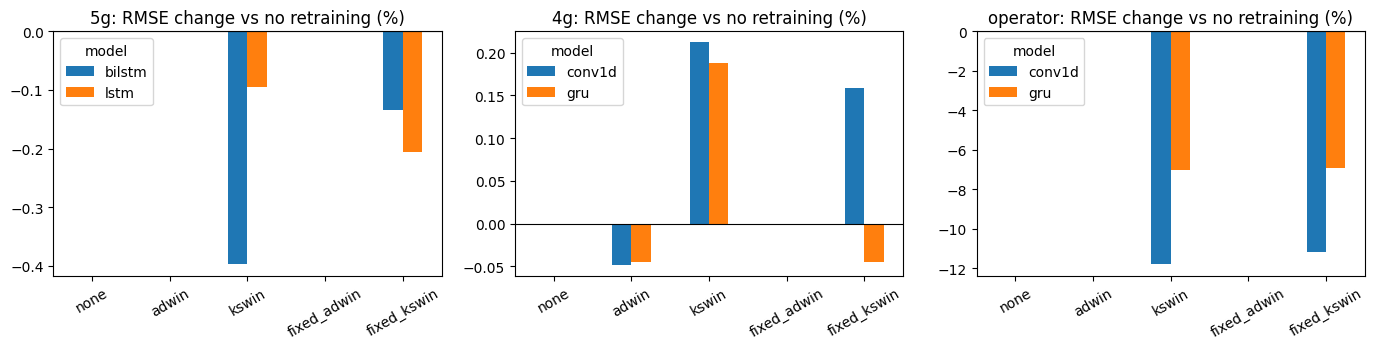

In [12]:
rows = []
for f in sorted(glob.glob(f"{CACHE}/*.pkl")):
    ds, kind, tr = os.path.basename(f)[:-4].split("__", 2)
    u = pickle.load(open(f, "rb"))
    for strat, r in u["strategies"].items():
        rows.append(dict(trace=tr, n=len(u["y"]), **metrics(u["y"], r["pred"], u["last"]),
                         run_id=f"{ds}|{COLSET[ds]}|w{WINDOW}|{kind}|s{SEED}|{strat}",
                         dataset=ds, model=kind, strategy=strat, n_retrains=len(r["alarms"]),
                         retrain_s=r["retrain_s"], capped=int(r["capped"])))
res = pd.DataFrame(rows); res.to_csv(f"{RES_B}/exp2_trace_results{SUF}.csv", index=False)

ORDER = ["none", "adwin", "kswin", "fixed_adwin", "fixed_kswin"]
S = res.groupby(["dataset", "model", "strategy"]).agg(RMSE=("RMSE", "mean"), MAE=("MAE", "mean"),
        R2_median=("R2", "median"), dir_acc=("dir_acc", "mean"), retrains=("n_retrains", "mean"),
        retrain_s=("retrain_s", "sum"), capped=("capped", "sum"), traces=("trace", "nunique")).reset_index()
base = S[S.strategy == "none"].set_index(["dataset", "model"]).RMSE
S["d_RMSE_%"] = [100 * (r.RMSE / base[(r.dataset, r.model)] - 1) for r in S.itertuples()]
S["strategy"] = pd.Categorical(S.strategy, ORDER, ordered=True)
S = S.sort_values(["dataset", "model", "strategy"]); S.to_csv(f"{RES_B}/exp2_summary{SUF}.csv", index=False)
pd.set_option("display.width", 220)
print(S.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, ds in zip(axes, DATASETS):
    sub = S[S.dataset == ds].pivot(index="strategy", columns="model", values="d_RMSE_%").reindex(ORDER)
    sub.plot.bar(ax=ax, rot=30); ax.axhline(0, c="k", lw=0.8)
    ax.set_title(f"{ds}: RMSE change vs no retraining (%)"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(f"{RES_B}/plot_exp2{SUF}.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Sanity check against Member A
The `none` strategy is exactly Member A's Experiment 1 model, so its per-trace RMSE must **match her `neural_trace_results.csv`** (seed 0, same traces). Tiny differences (about 1e-3 or less) are normal; large ones would mean something is wrong with the replay.

**You should see:** a maximum difference very close to 0 for every dataset and model.

In [13]:
na = pd.read_csv(f"{RES_A}/neural_trace_results.csv")
for ds in DATASETS:
    for kind in MODELS[ds]:
        a = na[na.run_id == f"{ds}|{COLSET[ds]}|w{WINDOW}|{kind}|s{SEED}"].set_index("trace")
        b = res[(res.dataset == ds) & (res.model == kind) & (res.strategy == "none")].set_index("trace")
        j = b.join(a, lsuffix="_b", rsuffix="_a", how="inner")
        print(f"{ds} {kind}: {len(j)} traces compared | max |RMSE difference| = "
              f"{(j.RMSE_b - j.RMSE_a).abs().max():.6f} | capped runs: {int(res[(res.dataset==ds)&(res.model==kind)].capped.sum())}")

5g lstm: 20 traces compared | max |RMSE difference| = 0.002238 | capped runs: 0
5g bilstm: 20 traces compared | max |RMSE difference| = 0.002561 | capped runs: 0
4g gru: 20 traces compared | max |RMSE difference| = 0.000177 | capped runs: 0
4g conv1d: 20 traces compared | max |RMSE difference| = 0.000154 | capped runs: 0
operator gru: 20 traces compared | max |RMSE difference| = 0.000013 | capped runs: 0
operator conv1d: 20 traces compared | max |RMSE difference| = 0.000009 | capped runs: 0
